In [19]:
import os

import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
from numba import njit, prange
from scipy.ndimage import gaussian_filter

In [20]:
colors = np.linspace(0, 1, 5)
mpl.rcParams["axes.prop_cycle"] = mpl.cycler(color=plt.cm.rainbow(colors))

#os.makedirs("../img", exist_ok=True)

# Algorithm 4 Sample-based Policy Iteration for Exploratory Optimal Stopping (SPI-λ-OS)

## Parameters

In [21]:
mu = 0.2
sigma = 0.2
rho = 0.5
kappa = 5.0
theta = 0.5
lambda_ = 0.2
zeta = 0.9

Nx = 250
Ny = 50
M = 20
T_max = 20
dt = 0.01

x_max = 5
x_grid = np.linspace(1e-4, x_max, Nx)
y_grid = np.linspace(1e-4, 1.0, Ny)

dx = x_grid[1] - x_grid[0]
dy = y_grid[1] - y_grid[0]

## Algorithm functions

In [22]:
@njit
def pi(x: float) -> float:
    return x**theta

In [23]:
@njit
def simulator_core(
    x_start: float,
    y_start: float,
    x_grid: np.ndarray,
    g: np.ndarray,
    M: int,
    dt: float,
    T_max: float,
    mu: float,
    sigma: float,
    rho: float,
    kappa: float,
    lambda_: float,
    theta: float,
    variant: int,
    Z: np.ndarray,
) -> float:
    """
    Simulate the core dynamics of the system.
    Corresponds to lines 4, 5, 6 and 7 in the algorithm from the article.

    Parameters:
    x_start: Starting value of the state variable X.
    y_start: Starting value of the state variable Y.
    x_grid: Grid of X values for interpolation.
    g: Array of g values corresponding to x_grid.
    M: Number of Monte Carlo simulations.
    dt: Time step for the simulation.
    T_max: Maximum time for the simulation.
    mu: Drift coefficient for X.
    sigma: Volatility coefficient for X.
    rho: Discount rate.
    kappa: Parameter for the reward function.
    lambda_: Parameter for the reward function.
    theta: Parameter for the reward function.
    variant: Variant of the model to use (1 or 2).
    Z: Pre-generated random numbers for the simulation.

    Returns:
    Average payoff over M simulations.
    """
    total_payoff = 0.0
    steps = int(T_max / dt)
    sqrt_dt = np.sqrt(dt)
    exp_neg_rho_dt = np.exp(-rho * dt)

    for m in range(M):
        X = x_start
        Y = y_start

        current_g = np.interp(X, x_grid, g)
        if Y > current_g:
            Y = current_g

        discount = 1.0
        path_payoff = 0.0

        for step_idx in range(steps):
            Y_safe = Y if Y > 1e-8 else 1e-8
            reward = ((pi(X) - rho * kappa) * Y - lambda_ * Y * np.log(Y_safe)) * dt
            path_payoff += discount * reward

            discount *= exp_neg_rho_dt

            dW = Z[m, step_idx]

            X = X + mu * X * dt + sigma * X * dW * sqrt_dt

            current_g = np.interp(X, x_grid, g)
            if Y > current_g:
                Y = current_g

        total_payoff += path_payoff

    return total_payoff / M

In [24]:
@njit(parallel=True)
def evaluate_u_monte_carlo(
    g: np.ndarray,
    x_grid: np.ndarray,
    y_grid: np.ndarray,
    M: int,
    dt: float,
    T_max: float,
    mu: float,
    sigma: float,
    rho: float,
    kappa: float,
    lambda_: float,
    theta: float,
    variant: int,
    Z: np.ndarray,
) -> np.ndarray:
    """
    Evaluate the function u over a grid of x and y values using Monte Carlo simulations.
    Corresponds to line 3 in the algorithm from the article.

    Parameters:
    g: Array of g values corresponding to x_grid.
    x_grid: Grid of X values for interpolation.
    y_grid: Grid of Y values for interpolation.
    M: Number of Monte Carlo simulations.
    dt: Time step for the simulation.
    T_max: Maximum time for the simulation.
    mu: Drift coefficient for X.
    sigma: Volatility coefficient for X.
    rho: Discount rate.
    kappa: Parameter for the reward function.
    lambda_: Parameter for the reward function.
    theta: Parameter for the reward function.
    variant: Variant of the simulation (1 or 2).
    Z: Pre-generated random numbers for the simulation.

    Returns:
    2D array of u values evaluated over the grid of x and y.
    """
    Nx = len(x_grid)
    Ny = len(y_grid)
    u = np.zeros((Nx, Ny))

    for i in prange(Nx):
        for j in range(Ny):
            u[i, j] = simulator_core(
                x_grid[i],
                y_grid[j],
                x_grid,
                g,
                M,
                dt,
                T_max,
                mu,
                sigma,
                rho,
                kappa,
                lambda_,
                theta,
                variant,
                Z,
            )
    return u

In [25]:
def policy_improvement(
    u: np.ndarray,
    g: np.ndarray,
    iteration: int,
    K: int,
    variant: str,
    tolerance: float = 1e-5,
) -> np.ndarray:
    """
    Improve the policy based on the current value function.
    Corresponds to line 9 in the algorithm from the article.

    Parameters:
    u: 2D array of the current value function evaluated over the grid of x and y.
    g: Array of current g values corresponding to x_grid.
    iteration: Current iteration number.
    K: Total number of iterations.
    variant: Variant of the simulation (1 or 2).
    tolerance: Tolerance level for detecting sign changes in the second derivative.

    Returns:
    Updated array of g values after policy improvement.
    """
    g_new = g.copy()

    current_sigma_u = 3.0 - (2.5 * (iteration / K))

    u_smooth = gaussian_filter(u, sigma=current_sigma_u)
    ux = np.gradient(u_smooth, dx, axis=0)
    uxy = np.gradient(ux, dy, axis=1)

    for i in range(Nx):
        j_boundary = np.searchsorted(y_grid, g[i], side="left") - 1
        j_boundary = max(j_boundary, 0)

        if uxy[i, j_boundary] < -tolerance:
            sign_change = np.where(np.diff(np.sign(uxy[i, :])))[0]
            valid = [j for j in sign_change if y_grid[j] < g[i]]

            if len(valid) > 0:
                j_target = max(valid)

                y1 = y_grid[j_target]
                y2 = y_grid[j_target + 1]

                f1 = uxy[i, j_target]
                f2 = uxy[i, j_target + 1]

                if abs(f2 - f1) > 1e-12:
                    g_new[i] = y1 - f1 * (y2 - y1) / (f2 - f1)
                else:
                    g_new[i] = y1

                g_new[i] = max(min(g_new[i], y2), y1)

    # Optional: smoothing of the boundary, gives pretty plots, but less accurate results, so commented out
    # current_sigma_g = 1.0 * (1 - iteration/K)
    # if current_sigma_g > 0.1:
    #     g = gaussian_filter(g_new, sigma=current_sigma_g)

    if variant == 1:
        for idx in range(1, len(g_new)):
            g_new[idx] = max(g_new[idx], g_new[idx - 1])

    g_new = np.clip(g_new, 0, 1.0)
    g_new[g_new > 0.98] = 1.0

    return g_new

In [26]:
def policy_iteration_MC(
    g0: callable, func_g_true: callable, variant: int = 1, K: int = 10, M: int = 100
) -> tuple[list[np.ndarray], np.ndarray, list[float]]:
    """
    Perform policy iteration using Monte Carlo simulations.
    Corresponds to lines 1 and 2 in the algorithm from the article.

    Parameters:
    g0: Callable that returns the initial guess for g.
    func_g_true: Callable that returns the true g values for error calculation.
    variant: Variant of the simulation (1 or 2).
    K: Total number of policy iteration steps.
    M: Number of Monte Carlo simulations for evaluating u.

    Returns:
    gs: List of g values at each iteration.
    g: Final g values after policy iteration.
    errors_g_true: List of maximum absolute errors between g and the true g values at each iteration.
    """
    g = g0()
    gs = [g.copy()]
    errors_g_true = []
    steps = int(T_max / dt)

    for k in range(K):
        Z = np.random.normal(0.0, 1.0, (M, steps))

        u = evaluate_u_monte_carlo(
            g,
            x_grid,
            y_grid,
            M,
            dt,
            T_max,
            mu,
            sigma,
            rho,
            kappa,
            lambda_,
            theta,
            variant,
            Z,
        )
        g = policy_improvement(u, g, k, K, variant)

        gs.append(g.copy())

        diff_mean = np.mean(np.abs(g - gs[-2]))
        error_g_true = np.max(np.abs(g - func_g_true()))
        errors_g_true.append(error_g_true)

        if diff_mean < 0.001:
            #print(f"Converged at iteration {k+1}")
            break

    return gs, g, errors_g_true

## Examples of initialization functions

In [27]:
def func_g_true():
    g = np.zeros_like(x_grid)

    P = rho - theta * mu - (sigma**2) * theta * (theta - 1) / 2
    alfa = (
        -(mu - sigma**2 / 2) - np.sqrt((mu - sigma**2 / 2) ** 2 + 2 * rho * sigma**2)
    ) / (sigma**2)
    for i, x in enumerate(x_grid):
        g[i] = min(
            np.exp((rho / lambda_) * ((x**theta / P) * (1 - theta / alfa) - kappa) - 1),
            1.0,
        )

    return g

In [28]:
def func_linear():
    g = np.zeros_like(x_grid)
    base = np.exp(-(1 + kappa * rho / lambda_))
    alpha = (
        -(mu - sigma**2 / 2) - np.sqrt((mu - sigma**2 / 2) ** 2 + 2 * rho * sigma**2)
    ) / (sigma**2)

    x1 = 0.5 * (-alpha * (kappa + lambda_ / rho) / (theta - alpha)) ** (-theta)

    for i, x in enumerate(x_grid):
        g[i] = min(base + (1.0 - base) / x1 * x, 1.0)
    return g

In [29]:
def func_exponential():
    g = np.zeros_like(x_grid)

    P = rho - zeta * mu - (sigma**2) * zeta * (zeta - 1) / 2
    alfa = (
        -(mu - sigma**2 / 2) - np.sqrt((mu - sigma**2 / 2) ** 2 + 2 * rho * sigma**2)
    ) / (sigma**2)

    for i, x in enumerate(x_grid):
        g[i] = min(
            np.exp((rho / lambda_) * ((x**zeta / P) * (1 - zeta / alfa) - kappa) - 1),
            1.0,
        )
    return g

In [30]:
def func_proposed():
    base = np.exp(-(1 + kappa * rho / lambda_))
    g = np.zeros_like(x_grid)

    for i, x in enumerate(x_grid):
        g[i] = min(base + x**2, 1.0)

    return g

## Outcome functions

In [31]:
def plot_results(
    gs: list[np.ndarray], g_final_0: np.ndarray, g_true_vals: np.ndarray, title: str
) -> None:
    """
    Plot the results of the policy iteration, including the true boundary, initial guess, K/2 iteration, and final boundary.

    Parameters:
    gs: A list of g values at each iteration.
    g_final_0: The final boundary g after convergence.
    g_true_vals: The true boundary values for comparison.
    title: The title for the plot.
    """
    K = len(gs) - 1

    plt.plot(
        x_grid,
        g_true_vals,
        color="gray",
        linestyle="--",
        linewidth=2,
        label="g_true (determined analytically)",
    )
    plt.plot(x_grid, gs[0], label="g_0(x)", linestyle="dashed", color="red")

    # Optional: plotting graphs for each iteration
    # for i in range(1, len(gs) - 1):
    #     plt.plot(x_grid, gs[i], alpha=0.4)

    # Graph for iteration K//2
    if K > 2:
        mid_k = K // 2
        plt.plot(
            x_grid, gs[mid_k], label=f"g(x) iter {mid_k}", color="orange", alpha=0.7
        )

    plt.plot(x_grid, g_final_0, label="g(x) final", linewidth=2, color="black")

    plt.xlabel("x")
    plt.ylabel("g(x)")
    plt.xlim(0, x_max)
    plt.title(title)
    plt.grid(True)
    plt.legend()

In [32]:
def plot_L1_error(gs: list, dx: float) -> None:
    """
    Plot the L1 error of the policy iteration.

    Parameters:
    gs: A list of g values at each iteration.
    dx: The step size for the discretization.
    """
    g_true_vals = func_g_true()
    gs_ = gs[1:]

    l1_errors = []

    for g_iter in gs_:
        error = np.sum(np.abs(g_iter - g_true_vals)) * dx
        l1_errors.append(error)

    plt.plot(
        range(1, len(l1_errors) + 1), l1_errors, marker="o", linestyle="-", color="blue"
    )
    plt.title("Convergence to g_true in the L1 norm")
    plt.xlabel("iteration")
    plt.ylabel("L1 error")

    plt.xticks(np.arange(1, len(l1_errors) + 1, 2))

    plt.grid(True)

In [33]:
def find_hitting_point(
    g_array: np.ndarray, x_array: np.ndarray, threshold: float = 0.999
) -> float:
    """
    Find the x value where g_array first reaches or exceeds the threshold.

    Parameters:
    g_array: The array of g values.
    x_array: The corresponding x values.
    threshold: The threshold value to find the hitting point.

    Returns:
    The x value where g_array first reaches or exceeds the threshold. Returns NaN if the threshold is not reached.
    """
    idx = np.argmax(g_array >= threshold)
    if idx == 0 and g_array[0] < threshold:
        return np.nan
    return x_array[idx]

## Function that runs the algorithm for different variants

In [34]:
def run_algorithm_4(
    g0_func: callable, func_true: callable, K: int, M: int, title_prefix: str, MC: int = 100
) -> None:
    """
    Run the policy iteration algorithm for two variants and plot the results.

    Parameters:
    g0_func: A callable that returns the initial guess for g.
    func_true: A callable that returns the true g values for comparison.
    K: The maximum number of iterations for policy iteration.
    M: The number of Monte Carlo samples.
    title_prefix: A string prefix for the plot titles.
    MC: The number of Monte Carlo simulations.

    Variants:
    1: Conditions as proposed in the article.
    2: No imposed monotonicity for better visibility of the results.
    """

    plt.figure(figsize=(14, 7))
    
    variant = 1
        
    g_true_vals = func_true()
    true_hit_1 = find_hitting_point(g_true_vals, x_grid)
    
    # Listy do zbierania wyników
    gs_list = []
    g_final_list = []
    l1_errors_list = []
    model_hit_1_list = []
    iterations_list = []  # <--- NOWA LISTA: na rzeczywistą liczbę iteracji
    
    for n in range(MC):
        gs_single, g_final_single, _ = policy_iteration_MC(
            g0_func, func_true, variant=variant, K=K, M=M
        )
            
        actual_iterations = len(gs_single) - 1
        iterations_list.append(actual_iterations)
    
        while len(gs_single) < K + 1:
            gs_single.append(gs_single[-1])
    
        l1_err = [np.sum(np.abs(g_iter - g_true_vals)) * dx for g_iter in gs_single[1:]]
        hit_1 = find_hitting_point(g_final_single, x_grid)
    
        gs_list.append(gs_single)
        g_final_list.append(g_final_single)
        l1_errors_list.append(l1_err)
        model_hit_1_list.append(hit_1)
    
    gs_mean = np.mean(np.array(gs_list), axis=0) 
    g_final_mean = np.mean(np.array(g_final_list), axis=0) 
    l1_errors_mean = np.mean(np.array(l1_errors_list), axis=0) 
    final_l1_mean = l1_errors_mean[-1]
    model_hit_1_mean = np.nanmean(model_hit_1_list)
        
    mean_iterations = np.mean(iterations_list)
    
    plt.subplot(1, 2, 1)
    plot_results(gs_mean, g_final_mean, g_true_vals, f"{title_prefix} | average of {MC} simulations")
    
    plt.subplot(1, 2, 2)
    plt.plot(
        range(1, len(l1_errors_mean) + 1),
        l1_errors_mean,
        marker="o",
        linestyle="-",
        color="blue",
        )
    plt.title(f"{title_prefix} | mean L1 error over {MC} simulations")
    plt.xlabel("Iteration")
    plt.ylabel("Mean L1 error")
    plt.grid(True)
    
    print(f"--- AVERAGE RESULTS FOR VARIANT {variant} ({MC} SIMULATIONS) ---")
    print(f"Mean iterations to converge: {mean_iterations:.2f} / {K}")  # <--- WYŚWIETLANIE ŚREDNIEJ
    print(f"Final Mean L1 error:        {final_l1_mean:.6f}")
    print(
        f"g_true reaches 1 at:        X = {true_hit_1:.4f}"
        if not np.isnan(true_hit_1)
        else "g_true does not reach 1."
        )
    print(
        f"Mean Model reaches 1 at:    X = {model_hit_1_mean:.4f}"
        if not np.isnan(model_hit_1_mean)
        else "Model on average does not reach 1."
        )
    print("-" * 50)
    
    plt.tight_layout()
    plt.show()

## Results

### analitycal initialization

--- AVERAGE RESULTS FOR VARIANT 1 (100 SIMULATIONS) ---
Mean iterations to converge: 1.72 / 5
Final Mean L1 error:        0.067855
g_true reaches 1 at:        X = 4.3976
Mean Model reaches 1 at:    X = 4.4619
--------------------------------------------------


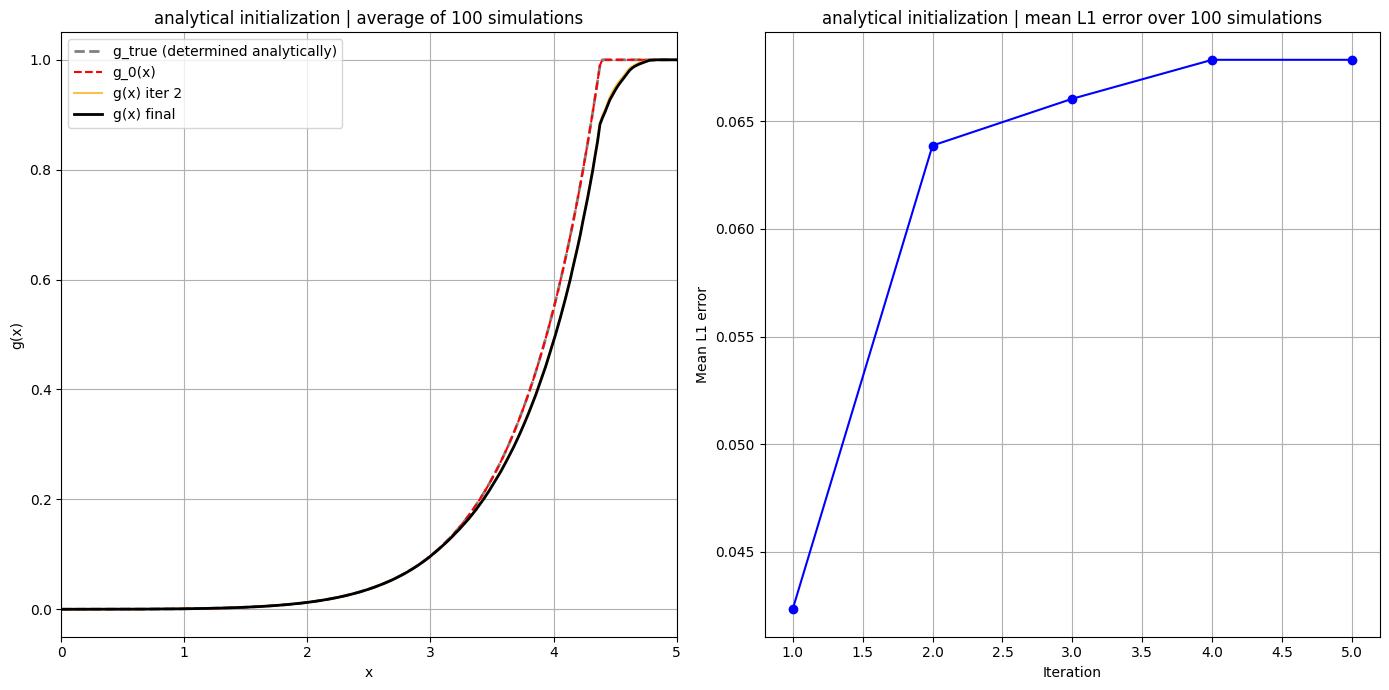

In [35]:
run_algorithm_4(
    func_g_true, func_g_true, K=5, M=M, title_prefix="analytical initialization"
)

### linear initialization

--- AVERAGE RESULTS FOR VARIANT 1 (100 SIMULATIONS) ---
Mean iterations to converge: 20.00 / 20
Final Mean L1 error:        1.204107
g_true reaches 1 at:        X = 4.3976
Mean Model reaches 1 at:    X = 4.5613
--------------------------------------------------


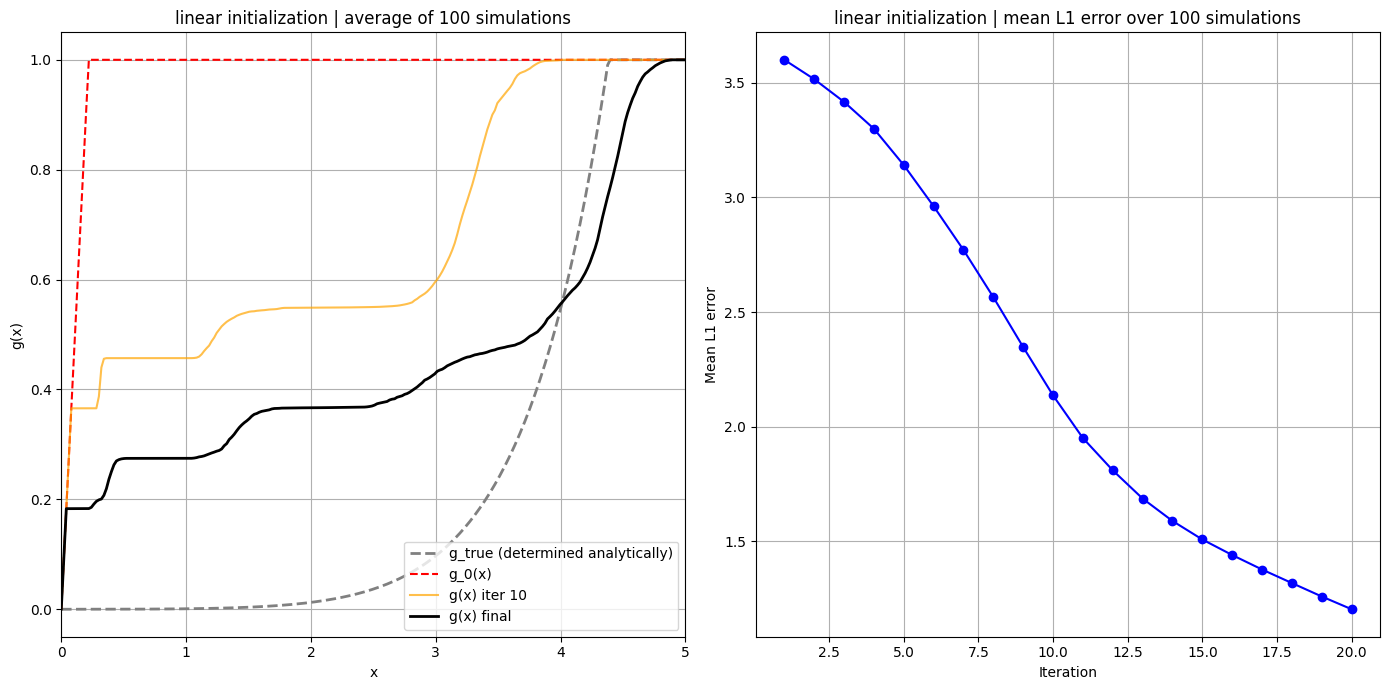

In [36]:
run_algorithm_4(
    func_linear, func_g_true, K=20, M=M, title_prefix="linear initialization"
)

### exponential initialization

--- AVERAGE RESULTS FOR VARIANT 1 (100 SIMULATIONS) ---
Mean iterations to converge: 17.09 / 20
Final Mean L1 error:        0.611362
g_true reaches 1 at:        X = 4.3976
Mean Model reaches 1 at:    X = 4.4267
--------------------------------------------------


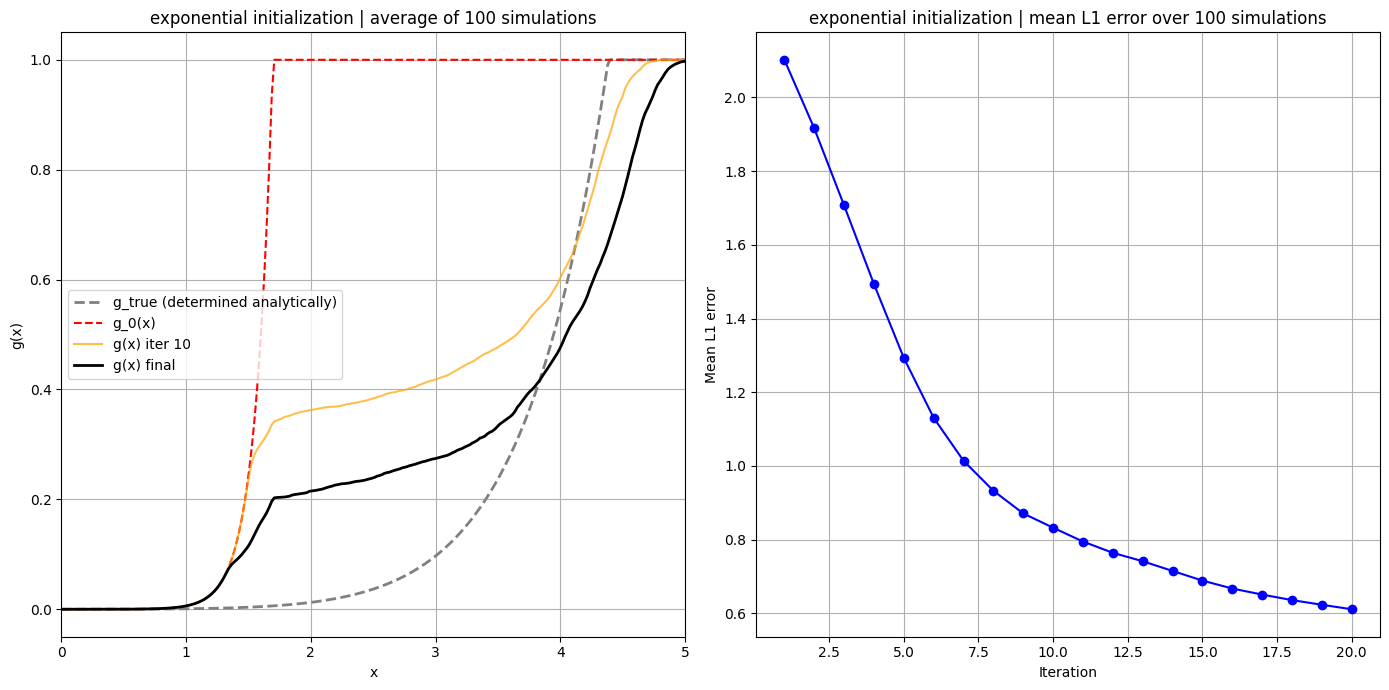

In [37]:
run_algorithm_4(
    func_exponential, func_g_true, K=20, M=M, title_prefix="exponential initialization"
)